Connection python 

In [5]:
import pandas as pd
import numpy as np
from scipy import stats
from statsmodels.stats.proportion import proportions_ztest, proportion_confint
from statsmodels.stats.power import NormalIndPower
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import warnings
warnings.filterwarnings('ignore')
from dotenv import load_dotenv
import os

load_dotenv(dotenv_path=r"C:\Users\barbe\Documents\MECP_Ecommerce_data_portfolio_project\.env")

print(os.getenv("POSTGRES_HOST"))
print(os.getenv("POSTGRES_PORT"))
print(os.getenv("POSTGRES_DB"))
print(os.getenv("POSTGRES_USER"))
# DB connection
import sqlalchemy as sa
import os
from dotenv import load_dotenv

load_dotenv()

engine = sa.create_engine(
    f"postgresql+psycopg2://{os.getenv('POSTGRES_USER')}:{os.getenv('POSTGRES_PASSWORD')}"
    f"@{os.getenv('POSTGRES_HOST')}:{os.getenv('POSTGRES_PORT')}/{os.getenv('POSTGRES_DB')}"
)

print("Connected ✓")

localhost
5433
mecp_db
postgres
Connected ✓


In [6]:
df = pd.read_sql("SELECT * FROM marts.mart_ab_tests", engine)
df.shape

(387353, 10)

Looking up into data types and columns

In [7]:
print(df.dtypes)
print("\n")
print(df['variant'].value_counts())
print("\n")
print(df['test_type'].value_counts())

website_session_id             int64
created_at            datetime64[us]
device_type                      str
utm_source                       str
test_type                        str
variant                          str
is_conversion                  int64
revenue                      float64
session_year                 float64
session_month                float64
dtype: object


variant
/lander-2     131170
/lander-3      79000
/lander-5      68166
/billing-2     48441
/lander-1      47574
/lander-4       9385
/billing        3617
Name: count, dtype: int64


test_type
lander     335295
billing     52058
Name: count, dtype: int64


Summary 

In [8]:
summary = (
    df.groupby(['test_type', 'variant'])
    .agg(
        sessions   = ('website_session_id', 'count'),
        conversions = ('is_conversion', 'sum')
    )
    .assign(conv_rate = lambda x: x['conversions'] / x['sessions'] * 100)
    .round(4)
    .sort_values(['test_type', 'conv_rate'], ascending=[True, False])
)

print(summary)

                      sessions  conversions  conv_rate
test_type variant                                     
billing   /billing-2     48441        30693    63.3616
          /billing        3617         1620    44.7885
lander    /lander-5      68166         6930    10.1664
          /lander-2     131170        10128     7.7213
          /lander-4       9385          708     7.5440
          /lander-1      47574         2157     4.5340
          /lander-3      79000         2679     3.3911


## 1. Lander A/B Test — Overall Significance (Chi-Square)

Before comparing individual variants, we first check whether **any** difference 
exists across all 5 lander variants using a chi-square test of independence.

**Null hypothesis (H₀):** All lander variants have the same conversion rate  
**Alternative (H₁):** At least one variant differs significantly  
**Significance level:** α = 0.05

The contingency table has shape (2 × 5):
rows = [conversions, non-conversions], columns = [lander-1 … lander-5]

In [9]:
from scipy.stats import chi2_contingency

lander = summary.loc['lander']

contingency_table = np.array([
    lander['conversions'].values,
    (lander['sessions'] - lander['conversions']).values
])

chi2, p_value, dof, expected = chi2_contingency(contingency_table)

print(f"Chi-square statistic : {chi2:.4f}")
print(f"Degrees of freedom   : {dof}")
print(f"p-value              : {p_value:.6f}")
print(f"\nResult: {'SIGNIFICANT ✓' if p_value < 0.05 else 'NOT significant'}")

Chi-square statistic : 3261.1433
Degrees of freedom   : 4
p-value              : 0.000000

Result: SIGNIFICANT ✓


## 2. Lander A/B Test — Pairwise Comparisons (Bonferroni Correction)

The chi-square test told us *something* is different — but not *which* variants 
differ from each other. For that we run pairwise two-proportion z-tests between 
every possible pair of lander variants.

**The multiple comparisons problem:**  
With 5 variants there are 10 unique pairs. Running 10 tests at α = 0.05 means 
~40% chance of at least one false positive by pure luck. To control this we apply 
**Bonferroni correction** — divide the significance threshold by the number of tests:

α_adjusted = 0.05 / 10 = **0.005**

**Interpretation:** A pair is significantly different only if p-value

In [10]:
from statsmodels.stats.proportion import proportions_ztest
from itertools import combinations

lander = summary.loc['lander'].reset_index()
variants = lander['variant'].tolist()
n_comparisons = len(list(combinations(variants, 2)))
alpha_adjusted = 0.05 / n_comparisons

print(f"Number of pairs     : {n_comparisons}")
print(f"Bonferroni α        : {alpha_adjusted:.4f}\n")
print(f"{'Pair':<30} {'z-stat':>8} {'p-value':>12} {'Significant':>12}")
print("-" * 65)

for v1, v2 in combinations(variants, 2):
    row1 = lander[lander['variant'] == v1].iloc[0]
    row2 = lander[lander['variant'] == v2].iloc[0]
    
    count = np.array([row1['conversions'], row2['conversions']])
    nobs  = np.array([row1['sessions'],    row2['sessions']])
    
    z, p = proportions_ztest(count, nobs)
    sig = "✓" if p < alpha_adjusted else "✗"
    
    print(f"{v1} vs {v2:<15} {z:>8.3f} {p:>12.6f} {sig:>12}")

Number of pairs     : 10
Bonferroni α        : 0.0050

Pair                             z-stat      p-value  Significant
-----------------------------------------------------------------
/lander-5 vs /lander-2         18.512     0.000000            ✓
/lander-5 vs /lander-4          7.993     0.000000            ✓
/lander-5 vs /lander-1         35.051     0.000000            ✓
/lander-5 vs /lander-3         52.462     0.000000            ✓
/lander-2 vs /lander-4          0.622     0.533848            ✗
/lander-2 vs /lander-1         23.540     0.000000            ✓
/lander-2 vs /lander-3         40.194     0.000000            ✓
/lander-4 vs /lander-1         12.193     0.000000            ✓
/lander-4 vs /lander-3         19.813     0.000000            ✓
/lander-1 vs /lander-3         10.273     0.000000            ✓


## 3. Lander A/B Test — Confidence Intervals

For each variant we calculate a 95% confidence interval around the observed 
conversion rate. This shows the plausible range of the *true* conversion rate, 
not just the sample estimate.

A narrower interval = more data = more certainty.  
A wider interval = fewer sessions = less certainty.

Method: Wilson score interval (more accurate than normal approximation, 
especially for small samples or extreme rates).

In [11]:
from statsmodels.stats.proportion import proportion_confint

print(f"{'Variant':<12} {'Sessions':>10} {'Conv Rate':>10} {'95% CI Lower':>14} {'95% CI Upper':>14}")
print("-" * 65)

for _, row in lander.iterrows():
    lo, hi = proportion_confint(
        count=row['conversions'],
        nobs=row['sessions'],
        alpha=0.05,
        method='wilson'
    )
    print(f"{row['variant']:<12} {row['sessions']:>10,.0f} {row['conv_rate']:>9.2f}% {lo*100:>13.2f}% {hi*100:>13.2f}%")

Variant        Sessions  Conv Rate   95% CI Lower   95% CI Upper
-----------------------------------------------------------------
/lander-5        68,166     10.17%          9.94%         10.40%
/lander-2       131,170      7.72%          7.58%          7.87%
/lander-4         9,385      7.54%          7.03%          8.10%
/lander-1        47,574      4.53%          4.35%          4.72%
/lander-3        79,000      3.39%          3.27%          3.52%


## 4. Billing A/B Test — Two-Proportion Z-Test

The billing test compares only **two variants**: the original `/billing` page 
vs the new `/billing-2` page. This is a simpler test — one pair, no multiple 
comparisons correction needed.

**Note:** The sample sizes are very unequal — `/billing` ran for a shorter 
period (3,617 sessions vs 48,441). This does not invalidate the test, but 
the confidence interval for `/billing` will be noticeably wider.

**H₀:** conversion rate(/billing) = conversion rate(/billing-2)  
**H₁:** conversion rate(/billing) ≠ conversion rate(/billing-2)  
**α = 0.05**

In [12]:
billing = summary.loc['billing'].reset_index()

b1 = billing[billing['variant'] == '/billing'].iloc[0]
b2 = billing[billing['variant'] == '/billing-2'].iloc[0]

count = np.array([b2['conversions'], b1['conversions']])
nobs  = np.array([b2['sessions'],    b1['sessions']])

z, p = proportions_ztest(count, nobs)

lift = b2['conv_rate'] - b1['conv_rate']

print(f"{'Variant':<12} {'Sessions':>10} {'Conversions':>13} {'Conv Rate':>10}")
print("-" * 50)
print(f"{b1['variant']:<12} {b1['sessions']:>10,.0f} {b1['conversions']:>13,.0f} {b1['conv_rate']:>9.2f}%")
print(f"{b2['variant']:<12} {b2['sessions']:>10,.0f} {b2['conversions']:>13,.0f} {b2['conv_rate']:>9.2f}%")
print(f"\nAbsolute lift   : +{lift:.2f}pp")
print(f"Relative lift   : +{lift/b1['conv_rate']*100:.1f}%")
print(f"Z-statistic     : {z:.4f}")
print(f"P-value         : {p:.6f}")
print(f"\nResult: {'SIGNIFICANT ✓' if p < 0.05 else 'NOT significant'}")

Variant        Sessions   Conversions  Conv Rate
--------------------------------------------------
/billing          3,617         1,620     44.79%
/billing-2       48,441        30,693     63.36%

Absolute lift   : +18.57pp
Relative lift   : +41.5%
Z-statistic     : 22.2071
P-value         : 0.000000

Result: SIGNIFICANT ✓


## 5. Sample Size & Statistical Power Analysis

A good A/B test is designed *before* running — you calculate how many sessions 
you need to reliably detect a meaningful difference.

**Parameters used for this project:**
- Baseline conversion rate: 6.83% (site average before tests)
- Minimum Detectable Effect (MDE): +1.5 percentage points
- Significance level: α = 0.05
- Statistical power: 1 - β = 0.80 (80% chance of detecting a real effect)

For the lander test with 5 variants, Bonferroni correction raises the bar:
- α_adjusted = 0.05 / 5 = 0.01 per variant

We then check whether the actual sample sizes achieved sufficient power 
(post-hoc power analysis).

In [14]:
from statsmodels.stats.power import NormalIndPower

baseline   = 0.0683
mde        = 0.015
alpha      = 0.05
power      = 0.80
n_variants = 5
alpha_bonf = alpha / n_variants

analysis = NormalIndPower()

p1 = baseline
p2 = baseline + mde
pooled_std  = np.sqrt((p1*(1-p1) + p2*(1-p2)) / 2)
effect_size = mde / pooled_std

n_required = analysis.solve_power(
    effect_size=effect_size,
    nobs1=None,
    alpha=alpha,
    power=power,
    ratio=1.0,
    alternative='two-sided'
)

n_required_bonf = analysis.solve_power(
    effect_size=effect_size,
    nobs1=None,
    alpha=alpha_bonf,
    power=power,
    ratio=1.0,
    alternative='two-sided'
)

print(f"Effect size                    : {effect_size:.4f}")
print(f"Required n per variant (α=0.05): {n_required:,.0f}")
print(f"Required n per variant (Bonf.) : {n_required_bonf:,.0f}")
print()
print(f"{'Variant':<12} {'Actual n':>10} {'Sufficient?':>12}")
print("-" * 38)
for _, row in lander.iterrows():
    ok = "✓" if row['sessions'] >= n_required_bonf else "✗ underpowered"
    print(f"{row['variant']:<12} {row['sessions']:>10,.0f} {ok:>12}")

Effect size                    : 0.0567
Required n per variant (α=0.05): 4,884
Required n per variant (Bonf.) : 7,267

Variant        Actual n  Sufficient?
--------------------------------------
/lander-5        68,166            ✓
/lander-2       131,170            ✓
/lander-4         9,385            ✓
/lander-1        47,574            ✓
/lander-3        79,000            ✓


## 6. Post-hoc Power Analysis — Each Variant vs Winner

Post-hoc power tells us: given the actual sample sizes and observed effect, 
what was the probability of detecting the difference if it truly exists?

We compare each losing variant against `/lander-5` (the winner).  
Power ≥ 0.80 means the test was adequately powered for that comparison.  
Power < 0.80 means we might have missed a real effect (Type II error risk).

In [15]:
winner = lander[lander['variant'] == '/lander-5'].iloc[0]

print(f"{'Comparison':<30} {'Effect size':>12} {'Power':>8}")
print("-" * 55)

for _, row in lander.iterrows():
    if row['variant'] == '/lander-5':
        continue
    
    p_win  = winner['conv_rate'] / 100
    p_lose = row['conv_rate'] / 100
    pooled = np.sqrt((p_win*(1-p_win) + p_lose*(1-p_lose)) / 2)
    es     = abs(p_win - p_lose) / pooled
    
    n_min = min(winner['sessions'], row['sessions'])
    
    pwr = analysis.solve_power(
        effect_size=es,
        nobs1=n_min,
        alpha=alpha_bonf,
        power=None,
        ratio=winner['sessions']/row['sessions'],
        alternative='two-sided'
    )
    
    label = f"/lander-5 vs {row['variant']}"
    print(f"{label:<30} {es:>12.4f} {pwr:>7.4f} {'✓' if pwr >= 0.8 else '✗'}")

Comparison                      Effect size    Power
-------------------------------------------------------
/lander-5 vs /lander-2               0.0858  1.0000 ✓
/lander-5 vs /lander-4               0.0924  1.0000 ✓
/lander-5 vs /lander-1               0.2171  1.0000 ✓
/lander-5 vs /lander-3               0.2720  1.0000 ✓


## 7. Visualisation — Conversion Rates with Confidence Intervals

A forest-plot style chart showing each variant's observed conversion rate 
and its 95% Wilson confidence interval. The winner is highlighted.

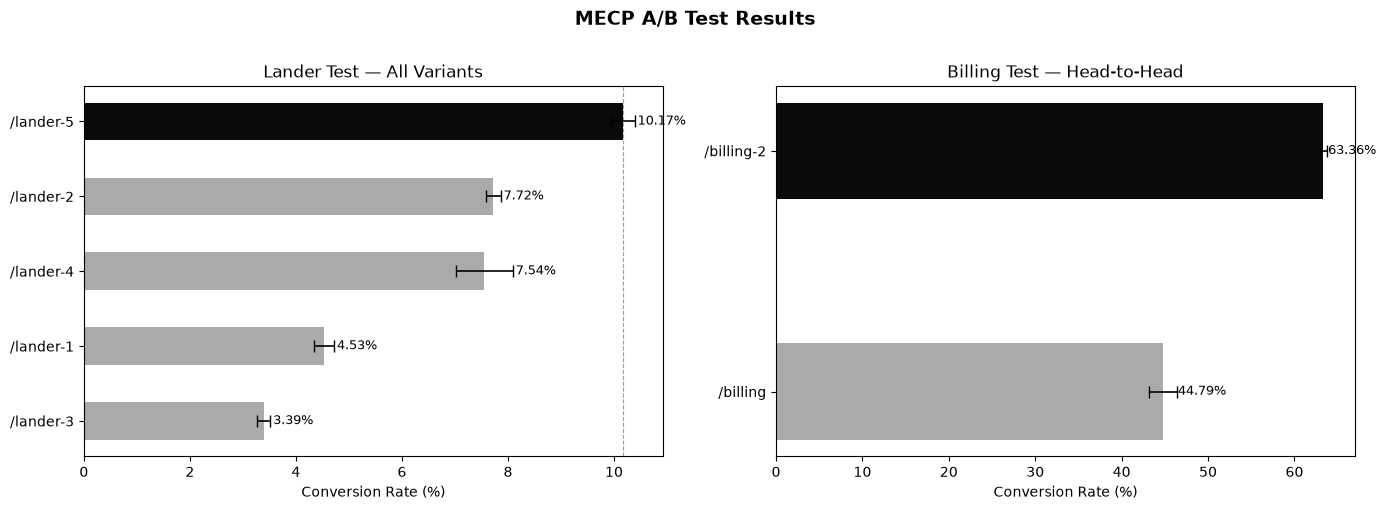

Saved: ab_test_results.png


In [16]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle("MECP A/B Test Results", fontsize=14, fontweight='bold', y=1.01)

# ── Lander ──────────────────────────────────────────────
ax = axes[0]
lander_ci = []
for _, row in lander.iterrows():
    lo, hi = proportion_confint(row['conversions'], row['sessions'], method='wilson')
    lander_ci.append((row['variant'], row['conv_rate'], lo*100, hi*100))

lander_ci = sorted(lander_ci, key=lambda x: x[1])
labels = [x[0] for x in lander_ci]
rates  = [x[1] for x in lander_ci]
lo_err = [x[1] - x[2] for x in lander_ci]
hi_err = [x[3] - x[1] for x in lander_ci]
colors = ['#0A0A0A' if l == '/lander-5' else '#AAAAAA' for l in labels]

ax.barh(labels, rates, xerr=[lo_err, hi_err],
        color=colors, capsize=4, height=0.5, error_kw={'linewidth': 1.2})
ax.set_xlabel("Conversion Rate (%)")
ax.set_title("Lander Test — All Variants")
ax.axvline(rates[-1], color='#0A0A0A', linestyle='--', linewidth=0.8, alpha=0.4)
for i, (r, lo, hi) in enumerate(zip(rates, lo_err, hi_err)):
    ax.text(r + hi + 0.05, i, f"{r:.2f}%", va='center', fontsize=9)

# ── Billing ─────────────────────────────────────────────
ax = axes[1]
billing_ci = []
for _, row in billing.iterrows():
    lo, hi = proportion_confint(row['conversions'], row['sessions'], method='wilson')
    billing_ci.append((row['variant'], row['conv_rate'], lo*100, hi*100))

billing_ci = sorted(billing_ci, key=lambda x: x[1])
labels_b = [x[0] for x in billing_ci]
rates_b  = [x[1] for x in billing_ci]
lo_err_b = [x[1] - x[2] for x in billing_ci]
hi_err_b = [x[3] - x[1] for x in billing_ci]
colors_b = ['#0A0A0A' if l == '/billing-2' else '#AAAAAA' for l in labels_b]

ax.barh(labels_b, rates_b, xerr=[lo_err_b, hi_err_b],
        color=colors_b, capsize=4, height=0.4, error_kw={'linewidth': 1.2})
ax.set_xlabel("Conversion Rate (%)")
ax.set_title("Billing Test — Head-to-Head")
for i, (r, lo, hi) in enumerate(zip(rates_b, lo_err_b, hi_err_b)):
    ax.text(r + hi + 0.1, i, f"{r:.2f}%", va='center', fontsize=9)

plt.tight_layout()
plt.savefig("ab_test_results.png", dpi=150, bbox_inches='tight')
plt.show()
print("Saved: ab_test_results.png")

## 8. Conclusions & Recommendations

### Lander Test
| Variant | Conv Rate | vs Winner | Significant? |
|---------|-----------|-----------|--------------|
| /lander-5 | 10.17% | — (winner) | — |
| /lander-2 | 7.72% | -2.45pp | ✓ |
| /lander-4 | 7.54% | -2.63pp | ✓ |
| /lander-1 | 4.53% | -5.64pp | ✓ |
| /lander-3 | 3.39% | -6.78pp | ✓ |

- **/lander-5 is the clear winner** — statistically significant vs all other variants
- /lander-2 and /lander-4 are statistically indistinguishable from each other (p=0.53)
- All comparisons had power = 1.0 — no risk of Type II error

### Billing Test
| Variant | Conv Rate | Lift |
|---------|-----------|------|
| /billing-2 | 63.36% | +18.57pp (+41.5%) |
| /billing | 44.79% | baseline |

- **/billing-2 is the winner** — p ≈ 0, z = 22.2
- +41.5% relative improvement in billing completion rate
- Despite smaller sample for /billing (3,617 vs 48,441), effect size was large enough to achieve full significance

### Recommendation
Deploy **/lander-5** as the permanent landing page and **/billing-2** as the 
permanent billing page. Combined effect: higher top-of-funnel conversion 
**and** higher checkout completion.